---
title: "3.6.b Amenaza por lluvias intensas y vendavales"
short_title: "b. Amenaza"
subtitle: "Lluvia extrema diaria, rachas de viento y registro de eventos en Leticia"
description: "Análisis de lluvias intensas y vientos fuertes en Leticia con ERA5 (1950–2026) y los registros de DesInventar y la UNGRD."
keywords: [lluvia extrema, vendaval, Rx1day, rachas, ERA5, Leticia]
---

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mromerot/leticia/blob/main/book/03_analisis/36_lluvias_vendavales/b_amenaza.ipynb)

In [1]:
# Preparación del entorno. En Colab instala el paquete del proyecto desde GitHub (1–2 minutos);
# en una copia local usa el paquete ya instalado con `pip install -e .`.
import sys, subprocess
if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "leticia @ git+https://github.com/mromerot/leticia"], check=True)
from leticia.libro import preparar, intentar
preparar()

Leticia recibe cerca de 3 000 mm de lluvia al año. Los aguaceros convectivos de la tarde, a menudo con
**ráfagas fuertes, granizo pequeño y descargas eléctricas**, son la causa de los vendavales que levantan techos de
zinc y de los encharcamientos en los barrios con drenaje insuficiente. El 22 de septiembre de 2024, en plena
sequía, un vendaval afectó los 32 barrios de la ciudad y llevó a declarar la calamidad pública
[@elpais2024vendaval].

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from leticia import clima, fuentes, hidro, viz
from leticia.config import parametros

pl = parametros()["lluvias"]
era = fuentes.clima_diario()
era = era[era.index.year < pd.Timestamp.today().year]
p = era["precipitation_sum"]

## 1. Régimen de lluvias

Lluvia media anual: **2.882 mm**.

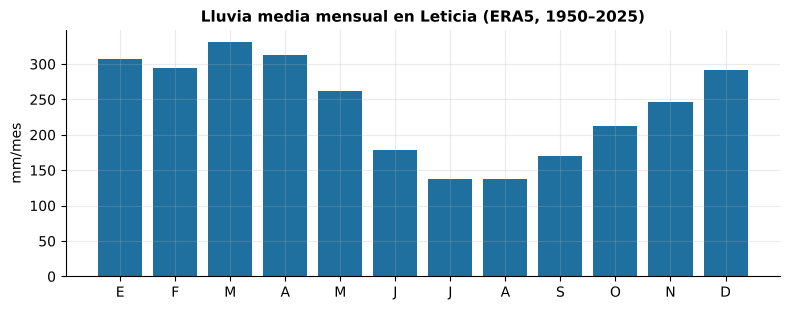

In [3]:
mensual = p.groupby([p.index.year, p.index.month]).sum().groupby(level=1).mean()
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(mensual.index, mensual, color=viz.AZUL_RIO)
ax.set_xticks(range(1, 13)); ax.set_xticklabels(list("EFMAMJJASOND"))
ax.set_ylabel("mm/mes")
ax.set_title(f"Lluvia media mensual en Leticia (ERA5, {p.index.year.min()}–{p.index.year.max()})")
fig.tight_layout()
display(Markdown(f"Lluvia media anual: **{p.groupby(p.index.year).sum().mean():,.0f} mm**.".replace(",", ".")))

## 2. Lluvia extrema

Tendencia 1980–presente: Rx1day +8.1 mm/década (p = 0.00); Rx5day +10.8 mm/década (p = 0.00). Las tendencias de lluvia de un reanálisis pueden reflejar cambios en las observaciones asimiladas; deben confirmarse con estaciones.

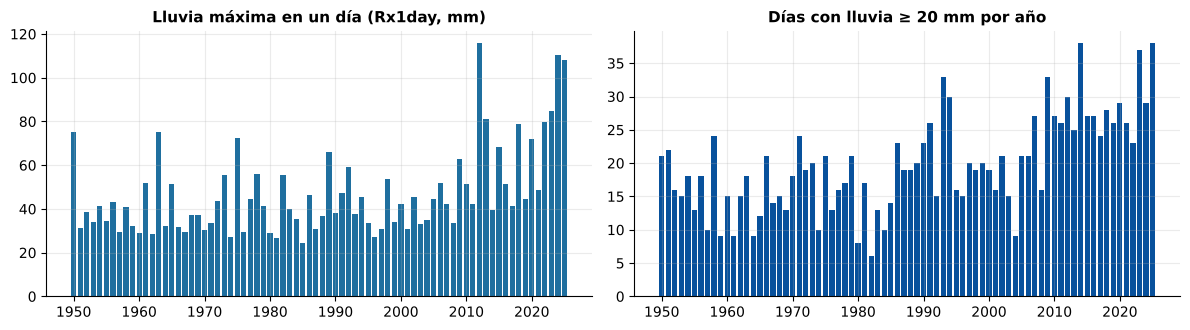

In [4]:
idx = clima.indices_lluvia(p, pl["umbral_lluvia_fuerte_mm"])
mk1, mk5 = hidro.mann_kendall(idx["rx1day"].loc[1980:]), hidro.mann_kendall(idx["rx5day"].loc[1980:])
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
ax[0].bar(idx.index, idx["rx1day"], color=viz.AZUL_RIO)
ax[0].set_title("Lluvia máxima en un día (Rx1day, mm)")
ax[1].bar(idx.index, idx["r20mm"], color="#08519c")
ax[1].set_title("Días con lluvia ≥ 20 mm por año")
fig.tight_layout()
display(Markdown(f"Tendencia 1980–presente: Rx1day {mk1['sen']*10:+.1f} mm/década (p = {mk1['p']:.2f}); "
                 f"Rx5day {mk5['sen']*10:+.1f} mm/década (p = {mk5['p']:.2f}). Las tendencias de lluvia de un reanálisis pueden "
                 "reflejar cambios en las observaciones asimiladas; deben confirmarse con estaciones."))

In [5]:
T = parametros()["periodos_retorno"]
x = idx["rx1day"].loc[1980:].values
ret = hidro.niveles_retorno_ic(x, T)
display(Markdown("**Lluvia diaria máxima por periodo de retorno (GEV por L-momentos, ERA5 1980–presente):**"))
display(ret.round(0).rename(columns={"nivel": "mm/día", "ic5": "IC 5 %", "ic95": "IC 95 %"}))

**Lluvia diaria máxima por periodo de retorno (GEV por L-momentos, ERA5 1980–presente):**

,mm/día,IC 5 %,IC 95 %
periodo_retorno,,,
2,45.00,40.00,50.00
5,63.00,55.00,73.00
10,78.00,66.00,89.00
25,101.00,82.00,114.00
50,121.00,95.00,138.00
100,144.00,108.00,168.00


In [6]:
viz.pie(viz.nota_fuente("clima_diario"))

*Fuente: ECMWF ERA5 (vía Open-Meteo) — Reanálisis ERA5, celda 0,25°.*

:::{important} ERA5 suaviza los aguaceros
Una celda de ~28 km promedia la lluvia de tormentas que duran una o dos horas y cubren pocos kilómetros: los
valores de ERA5 **subestiman** la lluvia extrema puntual. Las intensidades de diseño de drenaje deben salir de
las curvas intensidad-duración-frecuencia de la estación del aeropuerto Vásquez Cobo (IDEAM), cuya serie
automática empezó en 2009.
:::

## 3. Vientos fuertes

time,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
racha máxima anual (km/h),40.00,37.00,43.00,38.00,45.00,40.00,40.00,44.00,37.00,42.00,38.00
días con racha ≥ 50 km/h,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00


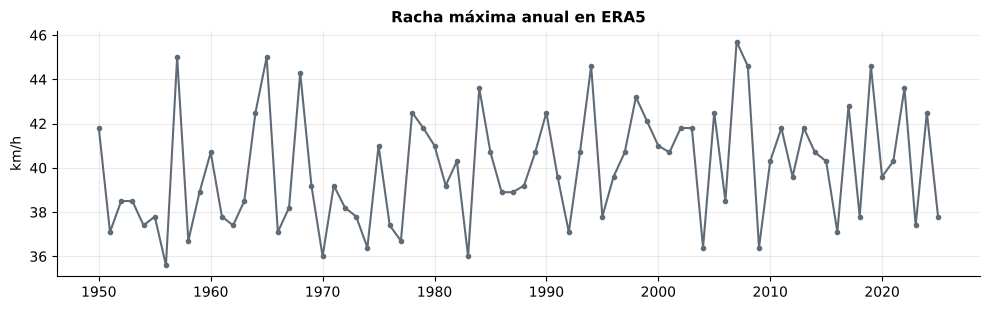

In [7]:
racha = era["wind_gusts_10m_max"]
anual = pd.DataFrame({"racha máxima anual (km/h)": racha.groupby(racha.index.year).max(),
                      f"días con racha ≥ {pl['umbral_racha_kmh']} km/h": (racha >= pl["umbral_racha_kmh"]).groupby(racha.index.year).sum()})
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(anual.index, anual.iloc[:, 0], color=viz.GRIS, marker="o", ms=3)
ax.set_ylabel("km/h")
ax.set_title("Racha máxima anual en ERA5")
fig.tight_layout()
display(anual.loc[2015:].T.round(0))

Las rachas de ERA5 rara vez superan 50 km/h porque el reanálisis no resuelve las corrientes descendentes de las
tormentas, que en la Amazonía pueden superar 80–100 km/h durante minutos. Por eso, para los vendavales el mejor
dato es el **registro de impactos**.

## 4. Registro de vendavales y lluvias intensas

In [8]:
di = fuentes.desinventar()
ung = fuentes.emergencias_ungrd()
v1 = di[di["evento"].str.contains("Vendaval|Lluvia|Tempestad|Granizada|Eléctrica", case=False, na=False)][["evento", "afectados", "vivafec", "vivdest"]]
v1 = v1.rename(columns={"vivafec": "viviendas_averiadas", "vivdest": "viviendas_destruidas"}).assign(fuente="DesInventar")
v2 = ung[ung["evento"].str.contains("VENDAVAL|LLUVIA|TORMENTA", case=False, na=False)][["evento", "personas", "viviendas_averiadas", "viviendas_destruidas"]]
v2 = v2.rename(columns={"personas": "afectados"}).assign(fuente="UNGRD")
eventos = pd.concat([v1, v2]).sort_index()
eventos = eventos[~(eventos.index.year.isin(v2.index.year) & (eventos.fuente == "DesInventar"))]
display(eventos.assign(año=eventos.index.year).set_index("año")[["evento", "afectados", "viviendas_averiadas", "viviendas_destruidas", "fuente"]])

,evento,afectados,viviendas_averiadas,viviendas_destruidas,fuente
año,,,,,
1999,Vendaval,4.00,1.00,0.00,DesInventar
1999,Vendaval,31.00,1.00,5.00,DesInventar
2010,Vendaval,21.00,4.00,0.00,DesInventar
2014,Vendaval,0.00,50.00,0.00,DesInventar
2014,Vendaval,0.00,25.00,0.00,DesInventar
2015,Vendaval,30.00,6.00,0.00,DesInventar
2021,VENDAVAL,185.00,37.00,0.00,UNGRD
2022,VENDAVAL,421.00,100.00,0.00,UNGRD
2024,VENDAVAL,140.00,35.00,0.00,UNGRD


**Lectura.** Los vendavales son eventos frecuentes y de impacto disperso: pocas víctimas, pero decenas a cientos
de viviendas destechadas. Su recurrencia en los registros (casi todos los años desde 2021) y la calamidad de 2024
justifican tratarlos como un escenario de riesgo propio en el PMGRD.